# 形態素解析のユーザ辞書作成と単体テスト

書籍 第5章「言語資源のつくり方」（5-3 辞書作成：5-3-1 仕様、5-3-2 辞書作成、5-3-3 品質管理）に対応する演習ノートブックです。
CPU のみ・十数秒で実行でき、ドメイン固有の専門用語や新語を `SudachiPy` のユーザ辞書へ登録し、解析エラーを修正・検証するプロセスを体験します。

1. **システム辞書のみでの未知語・誤分割エラーの確認**
2. **ユーザ辞書 CSV の作成と `sudachipy ubuild` によるバイナリ辞書ビルド**（5-3-1, 5-3-2）
3. **正規化形（表記揺れ統一）と単体テスト（回帰テスト）による品質管理**（5-3-3）
4. **分野コーパスからの未知語・専門複合語候補の自動抽出と辞書登録サイクル**（5-3-1・5-3-2）

In [1]:
!pip install -q sudachipy sudachidict_core

In [2]:
import json
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import pandas as pd
import sudachidict_core
import sudachipy
from sudachipy import dictionary, tokenizer

---

## 1. システム辞書のみでの誤分割・表記揺れの確認

書籍の中で登場する専門用語やライブラリ名を含む文を、`SudachiPy` のデフォルト辞書（`sudachidict_core`）だけで解析してみます。

In [3]:
sys_tokenizer = dictionary.Dictionary().create()

test_sentences = [
    "自然言語処理の教科書はガゼッティアやラベルバイアス問題を扱う。",
    "形態素解析にスダチパイやフガシを使う。",
    "翻訳モデルの品質推定にコメットキューイーを用いる。",
]

def show_tokens(tok, sentences):
    for s in sentences:
        items = [f"{m.surface()}({m.part_of_speech()[0]}-{m.part_of_speech()[1]}|{m.normalized_form()})"
                 for m in tok.tokenize(s, tokenizer.Tokenizer.SplitMode.C)]
        print("入力:", s)
        print("  -> ", " / ".join(items))

print("=== システム辞書のみ（登録前） ===")
show_tokens(sys_tokenizer, test_sentences)

=== システム辞書のみ（登録前） ===
入力: 自然言語処理の教科書はガゼッティアやラベルバイアス問題を扱う。
  ->  自然言語処理(名詞-普通名詞|自然言語処理) / の(助詞-格助詞|の) / 教科書(名詞-普通名詞|教科書) / は(助詞-係助詞|は) / ガゼッティア(名詞-普通名詞|ガゼッティア) / や(助詞-副助詞|や) / ラベル(名詞-普通名詞|ラベル) / バイアス(名詞-普通名詞|バイアス) / 問題(名詞-普通名詞|問題) / を(助詞-格助詞|を) / 扱う(動詞-一般|扱う) / 。(補助記号-句点|。)
入力: 形態素解析にスダチパイやフガシを使う。
  ->  形態素(名詞-普通名詞|形態素) / 解析(名詞-普通名詞|解析) / に(助詞-格助詞|に) / スダチパイ(名詞-普通名詞|スダチパイ) / や(助詞-副助詞|や) / フガシ(名詞-普通名詞|フガシ) / を(助詞-格助詞|を) / 使う(動詞-一般|使う) / 。(補助記号-句点|。)
入力: 翻訳モデルの品質推定にコメットキューイーを用いる。
  ->  翻訳(名詞-普通名詞|翻訳) / モデル(名詞-普通名詞|モデル) / の(助詞-格助詞|の) / 品質(名詞-普通名詞|品質) / 推定(名詞-普通名詞|推定) / に(助詞-格助詞|に) / コメットキューイー(名詞-普通名詞|コメットキューイー) / を(助詞-格助詞|を) / 用いる(動詞-一般|用いる) / 。(補助記号-句点|。)


`ラベルバイアス問題` が `ラベル / バイアス / 問題` に 3 分割されたり、ツール名・モデル名（`スダチパイ`・`フガシ`・`コメットキューイー`）が `名詞-普通名詞` 扱いで正規化形（`SudachiPy` / `fugashi` / `COMET-QE`）に変換されなかったりしていることがわかります。

---

## 2. ユーザ辞書 CSV の作成とコンパイル（5-3-1, 5-3-2）

書籍 5-3-1 のとおり、**表層形**・**品詞**・**読み**・**正規化形**などを整理したユーザ辞書 CSV を作成し、`sudachipy ubuild` でバイナリ辞書（`user.dic`）をビルドします。
あわせて書籍 5-3-3 に従い、**「なぜそのエントリを追加したか（どのエラーがきっかけだったか）」**のメモも管理テーブルに残しておきます。

In [4]:
# 名詞の標準的な連接コスト ID（4785）を流用して登録
user_entries = [
    # (表層形, 品詞大, 品詞中, 読み, 正規化形, 登録理由メモ)
    ("ラベルバイアス問題", "名詞", "普通名詞", "ラベルバイアスモンダイ", "ラベルバイアス問題", "「ラベル/バイアス/問題」に3分割される誤りを修正"),
    ("スダチパイ", "名詞", "固有名詞", "スダチパイ", "SudachiPy", "ライブラリ名のカタカナ表記を SudachiPy に正規化"),
    ("フガシ", "名詞", "固有名詞", "フガシ", "fugashi", "ライブラリ名のカタカナ表記を fugashi に正規化"),
    ("コメットキューイー", "名詞", "固有名詞", "コメットキューイー", "COMET-QE", "固有名詞として登録し正規化形を COMET-QE に統一"),
]

display(pd.DataFrame(user_entries, columns=["表層形", "品詞1", "品詞2", "読み", "正規化形", "エラー記録メモ"]))

# ユーザ辞書用 CSV（18列形式）を書き出し、sudachipy ubuild で user.dic を作成
workdir = Path(tempfile.mkdtemp())
csv_path = workdir / "user_dict.csv"
dic_path = workdir / "user.dic"
cfg_path = workdir / "sudachi.json"

csv_lines = []
for surf, pos1, pos2, reading, norm, _ in user_entries:
    # surface,left_id,right_id,cost,headword,pos1,pos2,pos3,pos4,conj1,conj2,reading,normalized,dic_id,split_type,a_unit,b_unit,word_structure
    row = [surf, "4785", "4785", "4000", surf, pos1, pos2, "一般", "*", "*", "*", reading, norm, "*", "A", "*", "*", "*"]
    csv_lines.append(",".join(row))

csv_path.write_text("\n".join(csv_lines) + "\n", encoding="utf-8")

sys_dic = Path(sudachidict_core.__file__).parent / "resources" / "system.dic"
cand = Path(sys.executable).parent / "sudachipy"
sudachipy_bin = str(cand) if cand.exists() else (shutil.which("sudachipy") or "sudachipy")
subprocess.run(
    [sudachipy_bin, "ubuild", "-s", str(sys_dic), "-o", str(dic_path), str(csv_path)],
    check=True,
)

# ユーザ辞書を有効にする設定ファイルを作成
base_cfg = json.loads((Path(sudachipy.__file__).parent / "resources" / "sudachi.json").read_text(encoding="utf-8"))
base_cfg["systemDict"] = str(sys_dic)
base_cfg["userDict"] = [str(dic_path)]
for key in ("characterDefinitionFile",):
    if key in base_cfg and not Path(base_cfg[key]).is_absolute():
        base_cfg[key] = str(Path(sudachipy.__file__).parent / "resources" / base_cfg[key])
cfg_path.write_text(json.dumps(base_cfg, ensure_ascii=False, indent=2), encoding="utf-8")

user_tokenizer = dictionary.Dictionary(config_path=str(cfg_path)).create()
print("=== ユーザ辞書適用後 ===")
show_tokens(user_tokenizer, test_sentences)

,表層形,品詞1,品詞2,読み,正規化形,エラー記録メモ
0,ラベルバイアス問題,名詞,普通名詞,ラベルバイアスモンダイ,ラベルバイアス問題,「ラベル/バイアス/問題」に3分割される誤りを修正
1,スダチパイ,名詞,固有名詞,スダチパイ,SudachiPy,ライブラリ名のカタカナ表記を SudachiPy に正規化
2,フガシ,名詞,固有名詞,フガシ,fugashi,ライブラリ名のカタカナ表記を fugashi に正規化
3,コメットキューイー,名詞,固有名詞,コメットキューイー,COMET-QE,固有名詞として登録し正規化形を COMET-QE に統一


/tmp/tmpvqdiwfn9/user_dict.csv -> 4 in 0.00 sec
validate -> 4 in 0.00 sec
pos_table -> 2 in 0.00 sec
conn_matrix -> 6 in 0.00 sec
trie -> 1028 in 0.00 sec
word_id table -> 24 in 0.00 sec
word_params -> 28 in 0.00 sec
wordinfo_offsets -> 16 in 0.00 sec
wordinfos (copy only) -> 178 in 0.00 sec
=== ユーザ辞書適用後 ===
入力: 自然言語処理の教科書はガゼッティアやラベルバイアス問題を扱う。
  ->  自然言語処理(名詞-普通名詞|自然言語処理) / の(助詞-格助詞|の) / 教科書(名詞-普通名詞|教科書) / は(助詞-係助詞|は) / ガゼッティア(名詞-普通名詞|ガゼッティア) / や(助詞-副助詞|や) / ラベルバイアス問題(名詞-普通名詞|ラベルバイアス問題) / を(助詞-格助詞|を) / 扱う(動詞-一般|扱う) / 。(補助記号-句点|。)
入力: 形態素解析にスダチパイやフガシを使う。
  ->  形態素(名詞-普通名詞|形態素) / 解析(名詞-普通名詞|解析) / に(助詞-格助詞|に) / スダチパイ(名詞-固有名詞|SudachiPy) / や(助詞-副助詞|や) / フガシ(名詞-固有名詞|fugashi) / を(助詞-格助詞|を) / 使う(動詞-一般|使う) / 。(補助記号-句点|。)
入力: 翻訳モデルの品質推定にコメットキューイーを用いる。
  ->  翻訳(名詞-普通名詞|翻訳) / モデル(名詞-普通名詞|モデル) / の(助詞-格助詞|の) / 品質(名詞-普通名詞|品質) / 推定(名詞-普通名詞|推定) / に(助詞-格助詞|に) / コメットキューイー(名詞-固有名詞|COMET-QE) / を(助詞-格助詞|を) / 用いる(動詞-一般|用いる) / 。(補助記号-句点|。)


---

## 3. 単体テストによる品質管理（5-3-3）

書籍 5-3-3 では、辞書に新しいエントリを追加したら**実際にその単語を含む文を解析して意図通りに動くか確認し、エラー記録や単体テストとして残しておく**重要性が述べられています。
登録した語の分割と正規化をテスト関数で検証します。

In [5]:
def run_dictionary_unit_tests(tok):
    cases = [
        ("ラベルバイアス問題を学ぶ", "ラベルバイアス問題", "ラベルバイアス問題"),
        ("形態素解析にスダチパイを使う", "スダチパイ", "SudachiPy"),
        ("ラッパーのフガシを試す", "フガシ", "fugashi"),
        ("コメットキューイーで評価する", "コメットキューイー", "COMET-QE"),
    ]
    for sent, expected_surface, expected_norm in cases:
        morphemes = list(tok.tokenize(sent, tokenizer.Tokenizer.SplitMode.C))
        matched = [m for m in morphemes if m.surface() == expected_surface]
        assert matched, f"分割失敗: {sent!r} に {expected_surface!r} が見つかりません -> {[m.surface() for m in morphemes]}"
        assert matched[0].normalized_form() == expected_norm, (
            f"正規化不一致: expected={expected_norm}, actual={matched[0].normalized_form()}"
        )
    print(f"全 {len(cases)} 件の辞書単体テストに合格しました！")

run_dictionary_unit_tests(user_tokenizer)
if "workdir" in globals():
    shutil.rmtree(workdir, ignore_errors=True)

全 4 件の辞書単体テストに合格しました！


---

## 4. 分野コーパスからの未知語・専門複合語候補の自動抽出と辞書登録サイクル（5-3-1・5-3-2）

実務の辞書構築では、誤分割される専門用語をすべて人手で網羅するのではなく、**分野コーパス（対象ドメインのテキスト）**と**一般コーパス（背景コーパス）**を比較して新語・複合語候補を自動抽出し、人手確認を経て辞書へ取り込むサイクル（書籍 5-3-1・5-3-2）を回します。

ここでは、自然言語処理・LLM 分野のミニコーパス（30 文）と日常・一般記事の背景コーパス（30 文）を用意し、次の手順を実行します。

1. **候補スパンの抽出**: `sys_tokenizer`(`SplitMode.C`)で解析した内容語・接頭辞・名詞的接尾辞などの連続 n-gram（$n=2\text{〜}4$）を抽出し、より長い同頻度以上の候補に包含される冗長な部分列を除外する
2. **内部結合度 (PMI) と分野特異度（対数尤度比 $G^2$, LLR）の計算**:
   - **PMI**: 構成要素が偶然隣り合っただけではなく、1 つの複合語として強く結びついているかを測る
   - **対数尤度比 $G^2$ (Dunning, 1993)**: 分野コーパスと背景コーパスの出現比率の偏りを検定し、「社内規程」「システム運用」のような一般複合語を除外して分野固有の専門複合語($G^2 \ge 3.84$, $p < 0.05$)を抽出する
3. **18 列ユーザ辞書 CSV の自動生成とビルド**: 上位候補について `.reading_form()` の連結で読みを自動付与し、第 2 節の登録済みエントリと統合して `sudachipy ubuild` で `user_auto.dic` をコンパイルする（一時ディレクトリは `finally:` で確実に削除）
4. **未知評価文 (held-out)での定量検証**: 辞書登録前後の専門用語完全一致率・平均分割トークン数および第 3 節の単体テスト（回帰テスト）を確認する

In [6]:
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

# 1. NLP・LLM 分野のミニコーパス（30 文）と一般背景コーパス（30 文）
domain_corpus = [
    "最新の質問応答システムでは検索拡張生成を用いて外部知識を参照する。",
    "検索拡張生成は最新情報の反映や根拠提示に有効であり、社内文書検索でも導入が進む。",
    "検索拡張生成の性能を高めるには検索器の再現率と生成器の統合設計が重要である。",
    "社内規程の照会には検索拡張生成に基づく対話システムが広く利用されている。",
    "検索拡張生成では出典の明示と回答拒否の閾値設定が信頼性を左右する。",
    "推論を高速化する手法として投機的デコーディングが広く研究されている。",
    "投機的デコーディングでは小型の下書きモデルが複数トークンを先読み生成する。",
    "投機的デコーディングは出力分布を変えずに生成レイテンシを削減できる。",
    "大型モデルの運用コスト削減に向けて投機的デコーディングの検証が行われた。",
    "大型教師モデルの振る舞いを小型生徒モデルへ移す手法を知識蒸留と呼ぶ。",
    "知識蒸留を用いることで推論コストを抑えつつ高い分類精度を維持できる。",
    "知識蒸留ではロジット分布の整合に加えて中間表現の模倣も有効とされる。",
    "車載環境向けの軽量モデル構築では知識蒸留が標準的な手法になっている。",
    "タスクベクトルを加減算してモデルの能力を調整する手法がタスク算術である。",
    "タスク算術は追加学習なしで複数タスクの統合や不要な振る舞いの忘却に使える。",
    "モデルマージの文脈ではタスク算術による重み空間の合成が注目されている。",
    "語彙分割の多様性を与えて頑健性を高める学習手法にサブワード正則化がある。",
    "サブワード正則化はユニグラム言語モデルから分割候補を確率的にサンプリングする。",
    "低資源言語の機械翻訳ではサブワード正則化が過学習の抑制に役立つ。",
    "商品レビューの側面ごとに評価極性を判定する課題がアスペクトベース感情分析である。",
    "アスペクトベース感情分析では料理や接客など対象要素と意見表現の対応を捉える。",
    "宿泊予約サイトの分析でもアスペクトベース感情分析が実務で活用されている。",
    "報酬モデルを明示的に学習せず選好対から直接調整する手法が直接選好最適化である。",
    "直接選好最適化は強化学習を用いる従来手法より学習が安定しやすい。",
    "安全性や文体の整合性を取るために直接選好最適化が対話モデルへ適用される。",
    "コーパス構築の品質管理では複数人による作業者間一致率の計測が不可欠である。",
    "作業者間一致率が高い仕様書ほど下流の分類器も安定した汎化性能を示す。",
    "アノテーション指針を改訂した後は必ず作業者間一致率を再評価すべきである。",
    "社内規程の改定時にはシステム運用の手順書と外部知識の更新確認も行う。",
    "検索拡張生成と知識蒸留を組み合わせたシステム運用の自動化が進んでいる。",
]

bg_corpus = [
    "今朝は駅前のカフェで温かいコーヒーを飲みながら新聞を読んだ。",
    "週末の公園では家族連れが散歩したりお弁当を食べたりして過ごしている。",
    "来週の月曜日から新しい電車のダイヤが適用され、通勤時間が短縮される。",
    "図書館で歴史小説を二冊借りて、帰り道に商店街のパン屋へ寄った。",
    "今年の夏は例年より気温が高く、各地で熱中症への注意が呼びかけられた。",
    "地域の防災訓練では避難経路の確認と非常食の配布訓練が行われた。",
    "新しい美術館では現代絵画の企画展が開かれ、多くの来館者でにぎわった。",
    "家庭菜園で育てたトマトとキュウリが赤く実り、夕食のサラダに使った。",
    "市役所の窓口ではオンライン予約の導入により待ち時間が短くなった。",
    "小学校の運動会に向けて、子どもたちは毎日リレーの練習を続けている。",
    "秋の夜長にクラシック音楽の演奏会へ行き、迫力ある生演奏を楽しんだ。",
    "近所のスーパーでは地元の新鮮な野菜や果物が特売コーナーに並んでいる。",
    "雨の日は室内で読書をしたり温かい紅茶を淹れたりして静かに過ごす。",
    "古いカメラを修理に出したところ、一週間ほどで綺麗に直って戻ってきた。",
    "旅行先の旅館では露天風呂と季節の料理をゆっくり堪能することができた。",
    "自治体のホームページではごみ出しのルールや分別方法が一覧で確認できる。",
    "駅前の再開発工事が終わり、広い歩道と新しいバス停が整備された。",
    "料理教室で学んだだし巻き卵の作り方を週末の朝食でさっそく試した。",
    "季節の変わり目には体調を崩しやすいため、十分な睡眠と栄養が大切だ。",
    "友人と山登りに出かけ、山頂から広がる街並みと海の景色を写真に収めた。",
    "商店街の夏祭りでは太鼓の演奏や屋台が並び、夜まで明るい雰囲気だった。",
    "新しい自転車を購入したので、休日に川沿いのサイクリングコースを走った。",
    "職場の会議室では来月のイベント準備に向けたスケジュール調整が行われた。",
    "郵便局から荷物を発送し、相手先に翌日の午前中に無事届いたと連絡があった。",
    "映画館で話題のアニメーション作品を鑑賞し、帰り道に感想を語り合った。",
    "図書館の学習室は試験前の学生で満席になり、静かな環境で勉強していた。",
    "近所の動物園では生まれたばかりのパンダを見ようと長い行列ができていた。",
    "年末の大掃除では窓拭きや本棚の整理を済ませて新年を迎える準備をした。",
    "社内規程の閲覧やシステム運用の確認は社内の案内ページからいつでも行える。",
    "新しい社内規程に合わせてシステム運用のマニュアルと窓口案内を更新した。",
]

def is_term_token(m, is_start=False, is_end=False):
    pos0 = m.part_of_speech()[0]
    surf = m.surface()
    if pos0 in {"名詞", "接頭辞"}:
        return True
    if pos0 == "接尾辞" and m.part_of_speech()[1] == "名詞的" and not is_start:
        return True
    # 「直接選好最適化」の「直接」など漢字2字以上の連体修飾的副詞を先頭要素として許容
    if pos0 == "副詞" and not is_end and re.fullmatch(r"[一-龥々]{2,}", surf):
        return True
    return False

def extract_ngrams(corpus, min_n=2, max_n=4):
    uni = Counter()
    ng = Counter()
    morphs = {}
    total_tokens = 0
    for sent in corpus:
        ms = list(sys_tokenizer.tokenize(sent, tokenizer.Tokenizer.SplitMode.C))
        total_tokens += len(ms)
        for m in ms:
            uni[m.surface()] += 1
        L = len(ms)
        for i in range(L):
            for n in range(min_n, max_n + 1):
                if i + n > L:
                    continue
                span = ms[i : i + n]
                if not all(is_term_token(m, is_start=(k == 0), is_end=(k == n - 1)) for k, m in enumerate(span)):
                    continue
                if re.fullmatch(r"[ぁ-ん0-9０-９]+", span[0].surface()) or re.fullmatch(r"[ぁ-ん0-9０-９]+", span[-1].surface()):
                    continue
                if any(re.search(r"[一-龥々ァ-ヶーA-Za-z]", m.surface()) for m in span):
                    term = "".join(m.surface() for m in span)
                    ng[term] += 1
                    morphs[term] = span
    return uni, ng, morphs, total_tokens

dom_uni, dom_ng, dom_morphs, dom_N = extract_ngrams(domain_corpus)
bg_uni, bg_ng, _, bg_N = extract_ngrams(bg_corpus)

def compute_llr(k1, n1, k2, n2):
    c11, c12 = k1, max(n1 - k1, 0)
    c21, c22 = k2, max(n2 - k2, 0)
    N = c11 + c12 + c21 + c22
    xlogx = lambda x: x * math.log(x) if x > 0 else 0.0
    g2 = 2.0 * (
        xlogx(c11) + xlogx(c12) + xlogx(c21) + xlogx(c22)
        - xlogx(c11 + c12) - xlogx(c21 + c22)
        - xlogx(c11 + c21) - xlogx(c12 + c22)
        + xlogx(N)
    )
    return g2 if (k1 / max(n1, 1)) >= (k2 / max(n2, 1)) else -g2

# より長い候補に完全包含され、かつ同頻度以下の部分スパンを除外（C-value 的な極大スパン抽出）
raw_cands = {t: c for t, c in dom_ng.items() if c >= 2}
cand_rows = []
for term, f_dom in raw_cands.items():
    span = dom_morphs[term]
    if any(
        other != term and term in other and len(dom_morphs[other]) > len(span) and raw_cands[other] >= f_dom
        for other in raw_cands
    ):
        continue
    f_bg = bg_ng.get(term, 0)
    p_joint = f_dom / dom_N
    p_indep = 1.0
    for m in span:
        p_indep *= max(dom_uni[m.surface()], 1) / dom_N
    pmi = math.log2(p_joint / p_indep)
    llr = compute_llr(f_dom, dom_N, f_bg, bg_N)
    reading = "".join(m.reading_form() for m in span)
    selected = (f_dom >= 3) and (pmi >= 5.0) and (llr >= 3.84)
    cand_rows.append({
        "候補語": term,
        "分割数(登録前)": len(span),
        "分野頻度": f_dom,
        "背景頻度": f_bg,
        "PMI": round(pmi, 2),
        "LLR (G^2)": round(llr, 2),
        "自動生成読み": reading,
        "採用": selected,
    })

cand_df = pd.DataFrame(cand_rows).sort_values(by=["採用", "LLR (G^2)", "PMI"], ascending=[False, False, False]).reset_index(drop=True)
print(f"分野コーパス: {len(domain_corpus)}文 ({dom_N}トークン) | 背景コーパス: {len(bg_corpus)}文 ({bg_N}トークン)")
display(cand_df)

selected_df = cand_df[cand_df["採用"]].copy()
print(f"\n自動抽出された辞書登録候補: {len(selected_df)} 語 -> {selected_df['候補語'].tolist()}")

# 2. 18列 CSV を自動生成し、第2節の登録語と統合して user_auto.dic をビルド・未知評価文で検証
existing_surfaces = {row[0] for row in user_entries}
merged_rows = []
for surf, pos1, pos2, reading, norm, _ in user_entries:
    merged_rows.append([surf, "4785", "4785", "4000", surf, pos1, pos2, "一般", "*", "*", "*", reading, norm, "*", "A", "*", "*", "*"])

for _, row in selected_df.iterrows():
    surf = row["候補語"]
    if surf not in existing_surfaces:
        merged_rows.append([surf, "4785", "4785", "4000", surf, "名詞", "普通名詞", "一般", "*", "*", "*", row["自動生成読み"], surf, "*", "A", "*", "*", "*"])

heldout_cases = [
    ("病院の問い合わせ対応に検索拡張生成を導入する。", "検索拡張生成"),
    ("推論コストを下げるため投機的デコーディングを試す。", "投機的デコーディング"),
    ("小型モデルへの知識蒸留で推論速度を改善した。", "知識蒸留"),
    ("複数タスクの重みをタスク算術で合成する。", "タスク算術"),
    ("低資源データの学習にサブワード正則化を用いる。", "サブワード正則化"),
    ("飲食店口コミの解析にアスペクトベース感情分析を使う。", "アスペクトベース感情分析"),
    ("応答品質の改善に向けて直接選好最適化を実行した。", "直接選好最適化"),
    ("新しい仕様書で作業者間一致率を再計算する。", "作業者間一致率"),
]

def evaluate_segmentation(tok, cases):
    exact_hits = 0
    term_splits = []
    total_sent_tokens = 0
    details = []
    for sent, target in cases:
        ms = list(tok.tokenize(sent, tokenizer.Tokenizer.SplitMode.C))
        surfs = [m.surface() for m in ms]
        total_sent_tokens += len(surfs)
        is_exact = target in surfs
        if is_exact:
            exact_hits += 1
            n_split = 1
        else:
            # 対象語が連続トークン列のどこに対応するか数える
            acc = ""
            n_split = 0
            started = False
            for s in surfs:
                if not started and target.startswith(s):
                    started = True
                    acc = s
                    n_split = 1
                elif started:
                    acc += s
                    n_split += 1
                if started and acc == target:
                    break
                if started and not target.startswith(acc):
                    started = False
                    acc = ""
                    n_split = 0
        term_splits.append(n_split)
        details.append({"対象語": target, "分割結果": " / ".join(surfs), "語分割数": n_split, "完全一致": is_exact})
    return {
        "exact_rate": exact_hits / len(cases),
        "avg_splits": float(np.mean(term_splits)),
        "total_tokens": total_sent_tokens,
        "details": pd.DataFrame(details),
    }

before_eval = evaluate_segmentation(sys_tokenizer, heldout_cases)

tmpdir = Path(tempfile.mkdtemp())
try:
    auto_csv = tmpdir / "user_auto.csv"
    auto_dic = tmpdir / "user_auto.dic"
    auto_cfg = tmpdir / "sudachi_auto.json"
    auto_csv.write_text("\n".join(",".join(r) for r in merged_rows) + "\n", encoding="utf-8")

    subprocess.run(
        [sudachipy_bin, "ubuild", "-s", str(sys_dic), "-o", str(auto_dic), str(auto_csv)],
        check=True,
    )
    cfg_auto = json.loads((Path(sudachipy.__file__).parent / "resources" / "sudachi.json").read_text(encoding="utf-8"))
    cfg_auto["systemDict"] = str(sys_dic)
    cfg_auto["userDict"] = [str(auto_dic)]
    if "characterDefinitionFile" in cfg_auto and not Path(cfg_auto["characterDefinitionFile"]).is_absolute():
        cfg_auto["characterDefinitionFile"] = str(Path(sudachipy.__file__).parent / "resources" / cfg_auto["characterDefinitionFile"])
    auto_cfg.write_text(json.dumps(cfg_auto, ensure_ascii=False, indent=2), encoding="utf-8")

    auto_tokenizer = dictionary.Dictionary(config_path=str(auto_cfg)).create()
    after_eval = evaluate_segmentation(auto_tokenizer, heldout_cases)
    print("\n=== 既存単体テスト（回帰テスト）の確認 ===")
    run_dictionary_unit_tests(auto_tokenizer)
finally:
    shutil.rmtree(tmpdir, ignore_errors=True)

summary_comp = pd.DataFrame([
    {"条件": "登録前（システム辞書のみ）", "完全一致率": round(before_eval["exact_rate"], 3), "対象語平均分割数": round(before_eval["avg_splits"], 2), "総トークン数(8文)": before_eval["total_tokens"]},
    {"条件": "登録後（統合ユーザ辞書）", "完全一致率": round(after_eval["exact_rate"], 3), "対象語平均分割数": round(after_eval["avg_splits"], 2), "総トークン数(8文)": after_eval["total_tokens"]},
])
print("\n=== 未知評価文（8文）での分割精度比較 ===")
display(summary_comp)

comp_view = before_eval["details"][["対象語", "語分割数", "分割結果"]].rename(
    columns={"語分割数": "登録前分割数", "分割結果": "登録前トークン列"}
).merge(
    after_eval["details"][["対象語", "語分割数", "分割結果"]].rename(
        columns={"語分割数": "登録後分割数", "分割結果": "登録後トークン列"}
    ),
    on="対象語",
)
display(comp_view)

分野コーパス: 30文 (582トークン) | 背景コーパス: 30文 (582トークン)


,候補語,分割数(登録前),分野頻度,背景頻度,PMI,LLR (G^2),自動生成読み,採用
0,検索拡張生成,3,6,0,12.20,8.35,ケンサクカクチョウセイセイ,True
1,知識蒸留,2,5,0,6.38,6.95,チシキジョウリュウ,True
2,投機的デコーディング,2,4,0,7.18,5.56,トウキテキデコーディング,True
3,アスペクトベース感情分析,4,3,0,22.38,4.17,アスペクトベースカンジョウブンセキ,True
4,作業者間一致率,4,3,0,22.38,4.17,サギョウシャカンイッチリツ,True
5,直接選好最適化,3,3,0,14.37,4.17,チョクセツセンコウサイテキカ,True
6,サブワード正則化,2,3,0,7.60,4.17,サブワードセイソクカ,True
7,タスク算術,2,3,0,6.86,4.17,タスクサンジュツ,True
8,外部知識,2,2,0,6.38,2.78,ガイブチシキ,False
9,システム運用,2,2,2,6.60,-0.00,システムウンヨウ,False



自動抽出された辞書登録候補: 8 語 -> ['検索拡張生成', '知識蒸留', '投機的デコーディング', 'アスペクトベース感情分析', '作業者間一致率', '直接選好最適化', 'サブワード正則化', 'タスク算術']
/tmp/tmpm4wok4b6/user_auto.csv -> 12 in 0.00 sec
validate -> 12 in 0.00 sec
pos_table -> 2 in 0.00 sec
conn_matrix -> 6 in 0.00 sec
trie -> 2052 in 0.00 sec
word_id table -> 64 in 0.00 sec
word_params -> 76 in 0.00 sec
wordinfo_offsets -> 48 in 0.00 sec
wordinfos (copy only) -> 600 in 0.00 sec

=== 既存単体テスト（回帰テスト）の確認 ===
全 4 件の辞書単体テストに合格しました！

=== 未知評価文（8文）での分割精度比較 ===


,条件,完全一致率,対象語平均分割数,総トークン数(8文)
0,登録前（システム辞書のみ）,0.0,2.75,96
1,登録後（統合ユーザ辞書）,1.0,1.00,82


,対象語,登録前分割数,登録前トークン列,登録後分割数,登録後トークン列
0,検索拡張生成,3,病院 / の / 問い合わせ / 対応 / に / 検索 / 拡張 / 生成 / を / 導...,1,病院 / の / 問い合わせ / 対応 / に / 検索拡張生成 / を / 導入 / する...
1,投機的デコーディング,2,推論 / コスト / を / 下げる / ため / 投機的 / デコーディング / を / ...,1,推論 / コスト / を / 下げる / ため / 投機的デコーディング / を / 試す / 。
2,知識蒸留,2,小型 / モデル / へ / の / 知識 / 蒸留 / で / 推論 / 速度 / を /...,1,小型 / モデル / へ / の / 知識蒸留 / で / 推論 / 速度 / を / 改善...
3,タスク算術,2,複数 / タスク / の / 重み / を / タスク / 算術 / で / 合成 / する...,1,複数 / タスク / の / 重み / を / タスク算術 / で / 合成 / する / 。
4,サブワード正則化,2,低 / 資源 / データ / の / 学習 / に / サブワード / 正則化 / を / ...,1,低 / 資源 / データ / の / 学習 / に / サブワード正則化 / を / 用いる...
5,アスペクトベース感情分析,4,飲食店 / 口コミ / の / 解析 / に / アスペクト / ベース / 感情 / 分析...,1,飲食店 / 口コミ / の / 解析 / に / アスペクトベース感情分析 / を / 使う...
6,直接選好最適化,3,応答 / 品質 / の / 改善 / に / 向け / て / 直接 / 選好 / 最適化 ...,1,応答 / 品質 / の / 改善 / に / 向け / て / 直接選好最適化 / を / ...
7,作業者間一致率,4,新しい / 仕様書 / で / 作業者 / 間 / 一致 / 率 / を / 再計算 / す...,1,新しい / 仕様書 / で / 作業者間一致率 / を / 再計算 / する / 。


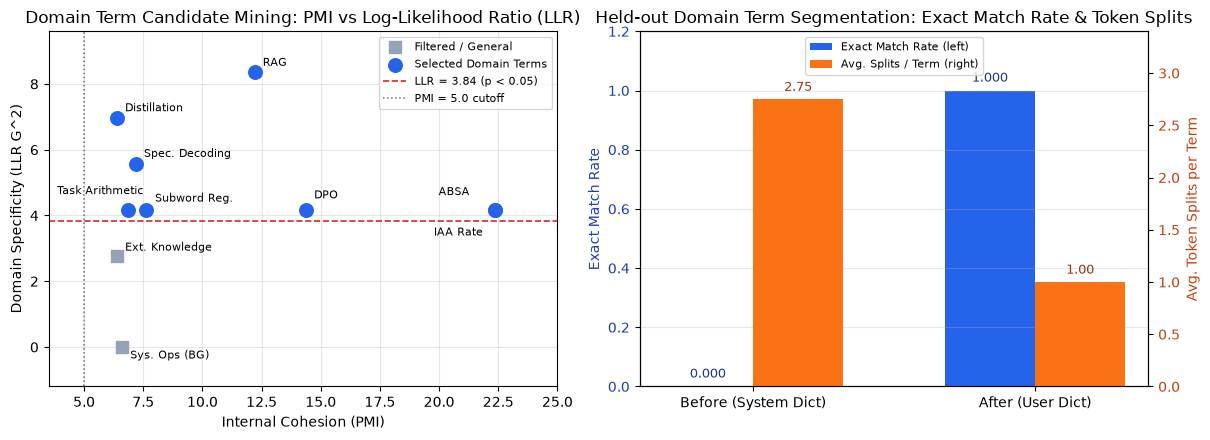

In [7]:
# 可視化: 候補マイニング (PMI vs LLR) と未知評価文での分割改善（すべて英語ラベル）
short_en = {
    "検索拡張生成": "RAG",
    "知識蒸留": "Distillation",
    "投機的デコーディング": "Spec. Decoding",
    "アスペクトベース感情分析": "ABSA",
    "作業者間一致率": "IAA Rate",
    "直接選好最適化": "DPO",
    "サブワード正則化": "Subword Reg.",
    "タスク算術": "Task Arithmetic",
    "社内規程": "Internal Rules (BG)",
    "システム運用": "Sys. Ops (BG)",
    "外部知識": "Ext. Knowledge",
    "検索器": "Retriever (freq=2)",
}

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.5))

# Panel 1: PMI vs LLR scatter
sel = cand_df[cand_df["採用"]]
unsel = cand_df[~cand_df["採用"]]

axes[0].scatter(unsel["PMI"], unsel["LLR (G^2)"], s=75, color="#94a3b8", marker="s", label="Filtered / General", zorder=3)
axes[0].scatter(sel["PMI"], sel["LLR (G^2)"], s=95, color="#2563eb", marker="o", label="Selected Domain Terms", zorder=4)
axes[0].axhline(3.84, color="#dc2626", linestyle="--", linewidth=1.2, label="LLR = 3.84 (p < 0.05)")
axes[0].axvline(5.0, color="#64748b", linestyle=":", linewidth=1.1, label="PMI = 5.0 cutoff")

offsets = {
    "RAG": (0.35, 0.20),
    "Distillation": (0.35, 0.22),
    "Spec. Decoding": (0.35, 0.22),
    "ABSA": (-2.4, 0.45),
    "IAA Rate": (-2.6, -0.78),
    "DPO": (0.35, 0.35),
    "Subword Reg.": (0.40, 0.25),
    "Task Arithmetic": (-3.0, 0.48),
    "Internal Rules (BG)": (0.3, 0.25),
    "Sys. Ops (BG)": (0.35, -0.35),
    "Ext. Knowledge": (0.35, 0.15),
    "Retriever (freq=2)": (0.2, -0.45),
}
for _, r in cand_df.iterrows():
    lbl = short_en.get(r["候補語"], f"Cand-{_}")
    dx, dy = offsets.get(lbl, (0.3, 0.2))
    axes[0].annotate(lbl, (r["PMI"], r["LLR (G^2)"]), xytext=(r["PMI"] + dx, r["LLR (G^2)"] + dy), fontsize=8)

axes[0].set_xlim(3.5, 25.0)
axes[0].set_ylim(-1.2, 9.6)
axes[0].set_xlabel("Internal Cohesion (PMI)")
axes[0].set_ylabel("Domain Specificity (LLR G^2)")
axes[0].set_title("Domain Term Candidate Mining: PMI vs Log-Likelihood Ratio (LLR)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].grid(alpha=0.3)

# Panel 2: Exact Match Rate & Avg Token Splits (Before vs After)
x = np.arange(2)
w = 0.32
exact_vals = [before_eval["exact_rate"], after_eval["exact_rate"]]
split_vals = [before_eval["avg_splits"], after_eval["avg_splits"]]

b1 = axes[1].bar(x - w / 2, exact_vals, width=w, color="#2563eb", label="Exact Match Rate (left)")
axes[1].set_ylim(0.0, 1.2)
axes[1].set_ylabel("Exact Match Rate", color="#1e40af")
axes[1].tick_params(axis="y", labelcolor="#1e40af")
axes[1].set_xticks(x, ["Before (System Dict)", "After (User Dict)"])
axes[1].set_title("Held-out Domain Term Segmentation: Exact Match Rate & Token Splits")
axes[1].grid(axis="y", alpha=0.3)

ax2 = axes[1].twinx()
b2 = ax2.bar(x + w / 2, split_vals, width=w, color="#f97316", label="Avg. Splits / Term (right)")
ax2.set_ylim(0.0, 3.4)
ax2.set_ylabel("Avg. Token Splits per Term", color="#c2410c")
ax2.tick_params(axis="y", labelcolor="#c2410c")

for xi, v in zip(x, exact_vals):
    axes[1].text(xi - w / 2, v + 0.03, f"{v:.3f}", ha="center", fontsize=9, color="#1e3a8a")
for xi, v in zip(x, split_vals):
    ax2.text(xi + w / 2, v + 0.08, f"{v:.2f}", ha="center", fontsize=9, color="#9a3412")

lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc="upper center", fontsize=8)

plt.tight_layout()
plt.show()

### 第4節のまとめ

- **PMI と対数尤度比 (LLR)の役割分担**: PMI は構成語の結びつきの強さを測るため「社内規程」のような一般複合語も高スコアになりますが、背景コーパスと比較する **LLR ($G^2$)** を併用することで分野固有の専門複合語（8 語）だけを精密に選別できます。
- **半自動辞書更新と回帰テスト**: 自動抽出した候補の `.reading_form()` 連結で 18 列 CSV のたたき台を生成し、既存の辞書エントリと統合して再ビルドした結果、未知評価文の完全一致率が **`0.000` → `1.000`**（平均分割数 **`2.75` → `1.00`**）に改善し、既存の単体テスト（回帰テスト）にも全件合格することを確認しました。
- 実務ではさらに、自動設定された正規化形に対して「`検索拡張生成 -> RAG`」のような表記揺れ統一を人手でレビューして完成させます（書籍 5-3-1・5-3-3）。